# EPR spin systems with `epreasy`

`epreasy` is a separate package in this repository (`import epreasy`) that
ports [EasySpin](https://easyspin.org), the MATLAB toolbox for EPR spectral
simulation by Stefan Stoll and co-workers, to Python. It keeps EasySpin's
interface: spin systems are dicts with EasySpin's field names, fields are in
mT, energies in MHz, Euler angles are EasySpin's passive rotations, and spin
numbers are 1-based. This guide covers the foundation that the simulators
will build on: spin systems, spin operators, the spin Hamiltonian and its
field split, energy levels, rotations, units and nuclear data. The
companion notebook is [`notebooks/epreasy.ipynb`](epreasy.ipynb)
([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/epreasy.ipynb)).

`epreasy` depends on `spynach` and changes nothing in it; the Spinach port
stays the core of this repository. For what carries over from EasySpin and
what differs, see [Coming from EasySpin](coming-from-easyspin.ipynb).

*Generated from [`docs/epreasy.md`](../epreasy.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [A spin system](#A-spin-system)
2. [Spin operators](#Spin-operators)
3. [The spin Hamiltonian and its field split](#The-spin-Hamiltonian-and-its-field-split)
4. [Energy levels](#Energy-levels)
5. [Rotations, units, nuclear data](#Rotations,-units,-nuclear-data)
6. [What is checked, and what is pending](#What-is-checked,-and-what-is-pending)

## A spin system

A spin system is a dict with EasySpin's fields: `S` (electron spins, default
1/2), `g` with `gFrame`, `Nucs` (a comma-separated isotope string), `A` with
`AFrame` (MHz), `D` with `DFrame` (MHz), `Q` with `QFrame`, electron-electron
couplings as `ee` or as `J`, `dip`, `dvec`, nuclear-nuclear couplings `nn`,
Stevens-operator terms `B2`..`B12`, line widths and strains. Numbers follow
MATLAB's shapes: a flat list is one row, so the three values below are the
principal values of one g tensor and `A=[16, 86]` would be an axial tensor.
`validatespinsys` checks the dict and returns a copy in EasySpin's processed
layout, with every tensor as a 2-D array of one row per spin and the derived
fields `I`, `gn`, `Spins` and `nStates` added.

In [1]:
import numpy as np

import epreasy as es

print(es.__version__)

spin_system = {
    "g": [2.0088, 2.0061, 2.0027],
    "gFrame": np.deg2rad([10, 20, 30]),
    "Nucs": "14N",
    "A": [16, 16, 86],  # MHz
    "AFrame": [0.3, 0.7, 1.1],  # radians, Euler angles of the A frame in the molecular frame
    "Q": [-0.5, 0.2],  # e^2 q Q / h in MHz and eta
    "lwpp": 0.3,  # mT, peak-to-peak Gaussian line width
}
full = es.validatespinsys(spin_system)
print(full["Spins"], full["nStates"])
print("Q principal values (MHz):", full["Q"].round(4), "   lw (FWHM, mT):", full["lw"].round(4))

0.1.0
[0.5 1. ] 6
Q principal values (MHz): [[ 0.1   0.15 -0.25]]    lw (FWHM, mT): [0.3532 0.    ]


Shorthands expand as in EasySpin: a scalar `g` is isotropic, two values are
axial, `D=[D, E]` gives the principal values `(-D/3+E, -D/3-E, 2D/3)`,
`Q=[eeqQ/h, eta]` the quadrupole principal values for the nucleus's spin,
and `lwpp` becomes `lw` (full width at half maximum). Nuclei of spin zero are
removed, and errors are EasySpin's: a missing `A`, a wrong size, `ee`
together with `J`, a mis-capitalised field name.

In [2]:
mn = {"S": 5 / 2, "D": [1000, 100], "DFrame": [0.2, 0.5, 0.9], "B4": [1, 2, -3, 0.5, 10, -0.5, 3, -2, 1], "Nucs": "55Mn", "A": 250}
print("D principal values:", es.validatespinsys(mn)["D"].round(2))
print("states:", es.hsdim(mn), " spins:", es.spinvec(mn))
try:
    es.validatespinsys({"nucs": "1H", "A": 1})
except ValueError as error:
    print("error:", error)

D principal values: [[-233.33 -433.33  666.67]]
states: 36  spins: [2.5 2.5]
error: Fix capitalization: Sys.nucs should be Sys.Nucs


## Spin operators

`sop` builds spin operator matrices in EasySpin's basis `|mS, mI, ...>` (first
spin slowest, `m` descending), from a vector of spin quantum numbers or a
spin system, with EasySpin's three syntaxes: one component letter per spin
(`'xye'`), component and spin number (`'x1y2'` or `'x1,y2'`), and
transition-selective operators (`'x(1|3)'` connects levels 1 and 3). The
letters are `e`, `x`, `y`, `z`, `+`, `-`, and `a`, `b` for the two states of a
spin-1/2. Several specifications give a tuple; `sparse=True` gives
`scipy.sparse` matrices.

In [3]:
Sx, Sy, Sz = es.sop(1, "x", "y", "z")
print("[Sx, Sy] = i Sz:", np.allclose(Sx @ Sy - Sy @ Sx, 1j * Sz))
print("diagonal of Sz for S = 1:", np.diag(Sz).real)
SxIz = es.sop([1 / 2, 1], "xz")
print("SxIz is 6 x 6, the same as", np.allclose(SxIz, es.sop([1 / 2, 1], "x1,z2")), "for 'x1,z2'")
print("Sx on the 1-3 transition of S = 1:")
print(es.sop(1, "x(1|3)").real)

[Sx, Sy] = i Sz: True
diagonal of Sz for S = 1: [ 1.  0. -1.]
SxIz is 6 x 6, the same as True for 'x1,z2'
Sx on the 1-3 transition of S = 1:
[[0.  0.  0.5]
 [0.  0.  0. ]
 [0.5 0.  0. ]]


`stev` gives the extended Stevens operators `O_k^q`; `q >= 0` is the cosine
operator, `q < 0` the sine one, and `k` runs up to `2S` (at most 12). Their
coefficients are the `B2`..`B12` rows of a spin system, ordered from `q = +k`
to `-k`.

In [4]:
O20 = es.stev(5 / 2, 2, 0)
S = 5 / 2
print("O_2^0 = 3 Sz^2 - S(S+1):", np.allclose(O20, 3 * es.sop(S, "z") @ es.sop(S, "z") - S * (S + 1) * np.eye(6)))
print("O_4^2 of the first spin in a two-spin system:", es.stev([5 / 2, 1 / 2], 4, 2, ispin=1).shape)

O_2^0 = 3 Sz^2 - S(S+1): True
O_4^2 of the first spin in a two-spin system: (12, 12)


## The spin Hamiltonian and its field split

The Hamiltonian is assembled as in EasySpin: the field-independent part `H0`
from the zero-field splitting (`ham_zf`, with the Stevens terms), the
electron-electron (`ham_ee`), hyperfine (`ham_hf`), nuclear quadrupole
(`ham_nq`) and nuclear-nuclear (`ham_nn`) terms, and the magnetic moment
operators `mux`, `muy`, `muz` (MHz/mT) from the electron and nuclear Zeeman
terms (`ham_ez`, `ham_nz`), so that for a field vector `B` in mT in the
molecular frame `H = H0 - B[0] mux - B[1] muy - B[2] muz`. This split is
what makes field sweeps cheap: `H0` and the moments are built once.

In [5]:
H0, mux, muy, muz = es.ham(spin_system)
B = np.array([0, 0, 340.0])  # mT along the molecular z axis
H = es.ham(spin_system, B)
print("dimension", H.shape, " Hermitian:", np.allclose(H, H.conj().T))
print("H equals H0 - B.mu:", np.allclose(H, H0 - B[2] * muz))
print("the components add up to H0:", np.allclose(H0, es.ham_zf(spin_system) + es.ham_hf(spin_system) + es.ham_nq(spin_system)))
H0_again, muzL = es.ham(spin_system, [120, -45, 300], split=True)
print("along a tilted field, H = H0 - |B| muzL:", np.allclose(es.ham(spin_system, [120, -45, 300]), H0_again - np.linalg.norm([120, -45, 300]) * muzL))

dimension (6, 6)  Hermitian: True
H equals H0 - B.mu: True
the components add up to H0: True
along a tilted field, H = H0 - |B| muzL: True


Tensor frames work as in EasySpin: `AFrame` are the Euler angles of the A
tensor's frame in the molecular frame, so the tensor in the molecular frame
is `R.T @ diag(A) @ R` with `R = erot(AFrame)`.

In [6]:
R = es.erot([0.3, 0.7, 1.1])
A_molecular = R.T @ np.diag([16, 16, 86]) @ R
tilted = es.ham_hf({"Nucs": "14N", "A": [16, 16, 86], "AFrame": [0.3, 0.7, 1.1]})
explicit = es.ham_hf({"Nucs": "14N", "A": A_molecular})
print("tilted principal values and the explicit full tensor agree:", np.allclose(tilted, explicit))

tilted principal values and the explicit full tensor agree: True


## Energy levels

`levels(spin_system, ori, B)` returns the energies (MHz, ascending) for the
field directions `ori` (`'x'`, `'y'`, `'z'`, `'xy'`, ..., or an array of polar
angles `[phi, theta]`) and magnitudes `B` (one value, a two-value range of 101
points, or a vector); `phi=` and `theta=` vectors are combined on a grid.
Singleton axes are dropped as in EasySpin, so a single orientation and field
gives a vector of levels, and `vectors=True` adds the eigenvectors.

In [7]:
E = es.levels(spin_system, "z", 340)
print("nitroxide levels at 340 mT along z (MHz):", E.round(1))
E_grid = es.levels(spin_system, [[0, 0], [np.pi / 3, np.pi / 4], [1.2, 2.0]], [0, 100, 350, 1200])
print("three orientations x four fields x six levels:", E_grid.shape)

nitroxide levels at 340 mT along z (MHz): [-4801.  -4766.5 -4732.6  4734.3  4766.8  4799. ]
three orientations x four fields x six levels: (3, 4, 6)


The Zeeman diagram of the Mn(II) system above, with the field along the
molecular z axis, is EasySpin's `levels` example; `D` splits the `S = 5/2`
manifold at zero field and the 55Mn hyperfine coupling splits each line into
six:

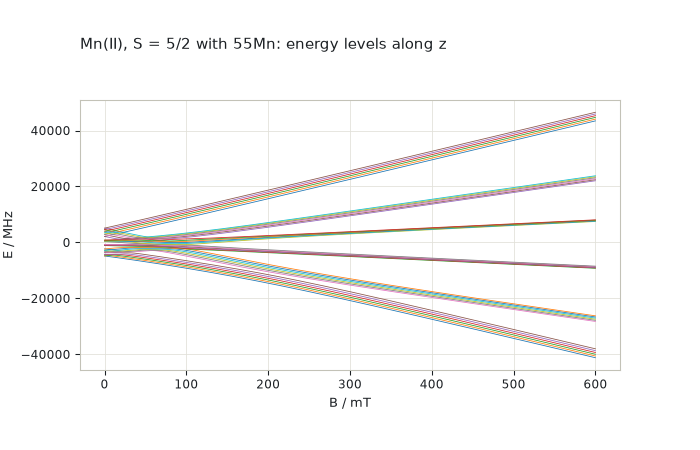

In [8]:
import plotly.graph_objects as go

fields = np.linspace(0, 600, 301)  # mT
E_mn = es.levels(mn, "z", fields)  # (301, 36)
fig = go.Figure()
for k in range(E_mn.shape[1]):
    fig.add_trace(go.Scatter(x=fields, y=E_mn[:, k], mode="lines", line={"width": 1}, showlegend=False))
fig.update_layout(title="Mn(II), S = 5/2 with 55Mn: energy levels along z", xaxis_title="B / mT", yaxis_title="E / MHz", width=700, height=450)
fig

## Rotations, units, nuclear data

`erot` is EasySpin's passive rotation matrix from Euler angles (z, y', z'');
`eulang` inverts it. Spynach's `euler2dcm` is Spinach's active rotation, the
transpose for the same angles. `ang2vec` and `vec2ang` convert between polar
angles and unit vectors.

In [9]:
from spynach.conventions import euler2dcm

angles = [0.4, 1.1, 2.3]
print("erot(angles) is euler2dcm(angles).T:", np.allclose(es.erot(angles), np.asarray(euler2dcm(angles)).T))
print("eulang(erot(angles)):", es.eulang(es.erot(angles)).round(6))
print("ang2vec(phi, theta):", es.ang2vec(0.5, 1.0).ravel().round(4))

erot(angles) is euler2dcm(angles).T: True
eulang(erot(angles)): [0.4 1.1 2.3]
ang2vec(phi, theta): [0.7385 0.4034 0.5403]


`unitconvert` converts between `cm^-1`, `eV`, `K`, `mT` and `MHz`, with a g
factor for the field conversions; `mt2mhz` and `mhz2mt` are the common pair.
The physical constants are module attributes (`es.bmagn`, `es.planck`,
`es.gfree`, ...). `nucdata` reads EasySpin's isotope table (351 isotopes):

In [10]:
print("350 mT at g_e is", es.mt2mhz(350).round(1), "MHz;  1 cm^-1 is", es.unitconvert(1, "cm^-1->MHz").round(1), "MHz")
data = es.nucdata("1H,14N,63Cu")
print("spins", data.spin, " gn", data.gn, " abundance", data.abund)
print("quadrupole moments (barn):", data.qm, " 63Cu natural abundance:", es.nucabund("63Cu"))

350 mT at g_e is 9808.7 MHz;  1 cm^-1 is 29979.2 MHz
spins [0.5 1.  1.5]  gn [5.58569468 0.403761   1.4824    ]  abundance [0.999885 0.99632  0.6917  ]
quadrupole moments (barn): [ 0.       0.02044 -0.22   ]  63Cu natural abundance: [0.6917]


## What is checked, and what is pending

`tests/epreasy/test_foundation.py` checks the closed forms (angular momentum
algebra, Stevens operators against their polynomial forms, the free-electron
and proton Zeeman energies, first-order hyperfine splittings, the zero-field
levels of a triplet, tensor frames) and `tests/epreasy/test_parity.py`
compares every stage with EasySpin 6.0.15 on five spin systems written by
`oracle/matlab/easyspin/dumps/esdump_ham.m`: a nitroxide with tilted frames, a
Cu(II) with two 14N, an S = 5/2 Mn(II) with D, E and a rank-4 Stevens term, a
radical pair with J, dipolar, antisymmetric and biquadratic exchange, and a
triplet with full g, D, A and Q matrices and two coupled nuclei. Spin and
Stevens operators and rotations agree to 1e-14 (the same arithmetic),
Hamiltonians and levels to 1e-12. The simulators (`pepper`, `garlic`, `salt`,
`chili`, `saffron`, `spidyan`, `curry`), `resfields`, line shapes and `esfit`
are the next phases; orbital angular momentum, higher-order Zeeman terms and
tilted Stevens-operator frames are not ported.